# 00 · Preparación de datos — Food Recognition 2022 (MyFoodRepo)

Este cuadernillo deja **todos los datos listos y comunes** para los 12 experimentos (A1–A4, B1–B4, C1–C4). Se ejecuta una sola vez y su salida se guarda como dataset de Kaggle.

**Qué hace**
1. Localiza el dataset (espejo de Kaggle `sainikhileshreddy/food-recognition-2022`) y carga las anotaciones COCO.
2. Re-etiqueta las clases **v2.0 → v2.1 (323 clases)** con `v2.1_breaking_class_mapping.json` y **reindexa los ids** de categoría a valores contiguos.
3. Crea las particiones (train / val / test) **por imagen** y las guarda en `splits.json`.
4. Hace un EDA básico y genera los COCO finales (con clases y agnósticos) más un dataset de **recortes** para los clasificadores: antes de filtrar por tamaño, las máscaras se **refinan con SAM 2** (con control de calidad) y cada recorte se entrega **con fondo negro**, para que el clasificador aprenda la textura del alimento y no el ruido del fondo.

> ⚠️ **Aviso metodológico.** El espejo de Kaggle contiene las imágenes de la **v2.0** (39,962 imágenes de entrenamiento). Aquí se re-etiquetan con las clases de la v2.1, pero el resultado **no es idéntico a la v2.1 oficial** (54,392 imágenes). En el informe debe describirse como *«MyFoodRepo v2.0 con la taxonomía de clases v2.1»*, y sus métricas no son comparables con el leaderboard.

**Salidas** (carpeta `food_prep/`): `classes.json`, `splits.json`, `coco_{train,val,test}.json`, `coco_agnostic_{train,val,test}.json`, `crops/` (fondo negro) + `crops_ctx/` (fondo original, opcional) + `crops_{split}.csv`, `refined_polys_{split}.json` (polígonos refinados por SAM 2), `eda.png`, `manifest.json`.

In [ ]:
# ----------------------------- CONFIGURACIÓN -----------------------------
CFG = dict(
    # --- datos de origen ---
    data_root   = None,    # None = autodetectar en /kaggle/input o descargar con kagglehub
    kaggle_slug = "sainikhileshreddy/food-recognition-2022",

    # --- mapeo v2.0 -> v2.1 (se busca en este orden: ruta local -> GitHub -> Google Drive) ---
    mapping_local    = None,   # p. ej. "/kaggle/input/mis-json/v2.1_breaking_class_mapping.json"
    mapping_urls     = ["https://raw.githubusercontent.com/AIcrowd/food-recognition-benchmark-starter-kit/master/utils/v2.1_breaking_class_mapping.json"],
    mapping_drive_id = "1MV6xltClrYittWsPWh12__fJLvlS_289",
    classes_local    = None,   # lista oficial de 323 clases (utils/classes_round2.json del starter kit)
    classes_urls     = ["https://raw.githubusercontent.com/AIcrowd/food-recognition-benchmark-starter-kit/master/utils/classes_round2.json"],
    # clases de v2.0 que no aparezcan en el mapeo: "error" (recomendado en la 1.ª ejecución) | "same_name" | "drop"
    unmapped_policy  = "error",
    expected_classes = 323,

    # --- particiones ---
    seed      = 42,
    test_frac = 0.10,          # fracción de train que se aparta como test propio

    # --- casi-duplicados (opcional, tarda unos minutos) ---
    run_duplicate_check = False,
    dup_hamming         = 4,   # distancia de Hamming (dHash de 64 bits) para considerar casi-duplicado

    # --- recortes para clasificadores ---
    make_crops         = True,
    crop_margin        = 0.10,    # margen relativo de la versión CON CONTEXTO (crops_ctx/, fondo original)
    crop_margin_masked = 0.02,    # margen de la versión de FONDO NEGRO (crops/): caja ajustada a la máscara refinada
    bbox_source        = "mask",  # caja que se da como prompt a SAM 2: "mask" = caja del polígono (recomendado) | "bbox" = caja guardada en el COCO
    crop_min_side      = 32,      # se descartan máscaras (ya refinadas) con lado menor a este valor (px de la foto real)
    crop_min_area_px   = 1024,    # se descartan máscaras refinadas con menos de este área (px de la foto real)
    crop_min_fill      = 0.10,    # se descartan máscaras refinadas que ocupan <10 % de su caja (objetos finos o dispersos)
    crop_max_side      = 256,     # el lado mayor del recorte se reduce a este valor (no se amplía)
    bg_color           = (0, 0, 0),  # color de fondo de crops/ (negro)
    mask_erode_px      = 1,       # erosiona la máscara N px (a tamaño final) para evitar el halo del fondo original
    save_context       = True,    # además de crops/ (fondo negro) guarda crops_ctx/ (mismo recorte con su fondo original)
    save_refined_polys = True,    # guarda refined_polys_{split}.json con los polígonos refinados (los coco_*.json NO se modifican)
    n_workers          = 8,

    # --- refinamiento de máscaras con SAM 2 (se ejecuta ANTES de los filtros de tamaño/relleno) ---
    use_sam2            = True,   # False = usa el polígono original como máscara (sigue habiendo fondo negro)
    sam2_model_id       = "facebook/sam2.1-hiera-base-plus",   # se descarga de Hugging Face (requiere internet); alternativas: ...-small, ...-large
    sam2_cfg            = None,   # sin internet: p. ej. "configs/sam2.1/sam2.1_hiera_b+.yaml"
    sam2_ckpt           = None,   # sin internet: ruta local del checkpoint (sam2.1_hiera_base_plus.pt)
    sam2_allow_cpu      = False,  # sin GPU se desactiva SAM 2 automáticamente (en CPU tardaría días)
    sam2_max_side       = 1024,   # la foto se reduce a este lado mayor para SAM 2 (internamente ya trabaja a 1024)
    sam2_min_prompt_side= 8,      # cajas con un lado menor (px reales) no sirven de prompt y se descartan
    sam2_box_expand     = 0.15,   # la máscara de SAM 2 se limita a la caja ampliada este % (evita fugas)
    sam2_max_neg        = 3,      # máx. puntos negativos (centros de instancias vecinas) por instancia
    sam2_min_score      = 0.80,   # puntuación mínima predicha por SAM 2 para aceptar la máscara
    sam2_min_iou        = 0.60,   # IoU mínimo entre la máscara de SAM 2 y el polígono original (si es menor, una de las dos está mal)
    sam2_fallback       = "polygon",  # máscara rechazada: "polygon" = se queda el polígono original (marcado en el CSV) | "drop" = se descarta
    sam2_comp_min_frac  = 0.05,   # se eliminan islas con menos de este % del componente mayor
    sam2_hole_max_frac  = 0.02,   # se rellenan huecos internos menores a este % del área
    sam2_dtype          = "auto", # "auto" = bf16 si la GPU es Ampere o superior (A100/L4), si no fp32 (T4 no tiene bf16 real) | "bf16" | "fp16" (más rápido en T4, pero pruébalo antes) | "fp32"
    sam2_test_images    = None,   # int (p. ej. 200) = MODO PRUEBA con N fotos por partición; None = todo
    resume              = True,   # reanuda si el proceso se cortó (guarda progreso en food_prep/_partial/)
    delete_partial_at_end = True, # borra _partial/ en el cierre (sección 8)

    # --- ejecución por lotes + guardado en Google Drive (Colab) ---
    batch_images        = 500,    # fotos por lote; al terminar cada lote se guarda un shard en Drive (lo máximo que se pierde si Colab se corta)
    max_batches         = None,   # parar de forma controlada tras N lotes en esta ejecución (None = sin límite)
    time_budget_min     = None,   # parar de forma controlada tras N minutos (p. ej. 600 para quedar bajo el límite de sesión de Colab)
    drive_sync          = True,   # guardar el progreso en Drive (solo actúa en Colab)
    drive_dir           = "/content/drive/MyDrive/food_prep_ckpt",

    out_dir = None,            # None = /kaggle/working/food_prep (o ./food_prep fuera de Kaggle)
)

In [ ]:
import os, sys, json, random, hashlib, warnings
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw): return x

IN_KAGGLE = Path("/kaggle/working").exists()
OUT = Path(CFG["out_dir"] or ("/kaggle/working/food_prep" if IN_KAGGLE else "./food_prep"))
OUT.mkdir(parents=True, exist_ok=True)
random.seed(CFG["seed"]); np.random.seed(CFG["seed"])
print("Salida en:", OUT.resolve())

Salida en: /content/food_prep


## 1. Localizar y cargar el dataset

In [ ]:
def _walk_find(root, target, max_depth=4):
    root = Path(root)
    if not root.exists(): return None
    base = len(root.parts)
    for dp, dn, _ in os.walk(root):
        if len(Path(dp).parts) - base >= max_depth: dn[:] = []
        if target in dn: return Path(dp) / target
    return None

def locate_raw_data():
    cands = [CFG["data_root"]] if CFG["data_root"] else []
    cands += ["/kaggle/input/food-recognition-2022",
              "/kaggle/input/datasets/sainikhileshreddy/food-recognition-2022"]
    for c in cands:
        for sub in (Path(c) / "raw_data", Path(c)):
            if (sub / "public_training_set_release_2.0").exists(): return sub
    hit = _walk_find("/kaggle/input", "public_training_set_release_2.0")
    if hit: return hit.parent
    # Fuera de Kaggle: descargar (OJO: baja también la carpeta hub/, que duplica las imágenes)
    try:
        import kagglehub
    except ImportError:
        os.system(f"{sys.executable} -m pip install -q kagglehub"); import kagglehub
    root = Path(kagglehub.dataset_download(CFG["kaggle_slug"]))
    for sub in (root / "raw_data", root):
        if (sub / "public_training_set_release_2.0").exists(): return sub
    hit = _walk_find(root, "public_training_set_release_2.0")
    if hit: return hit.parent
    raise FileNotFoundError("No se encontró public_training_set_release_2.0. Ajusta CFG['data_root'].")

RAW = locate_raw_data()
TRAIN_DIR, VAL_DIR = RAW / "public_training_set_release_2.0", RAW / "public_validation_set_2.0"
IMG_DIR = {"train": TRAIN_DIR / "images", "val": VAL_DIR / "images"}
print("Dataset en:", RAW)
print("(el test oficial no tiene anotaciones públicas: se crea un test propio a partir de train)")

100%|██████████| 4.91G/4.91G [04:35<00:00, 19.1MB/s]

Extracting files...


Dataset en: /root/.cache/kagglehub/datasets/sainikhileshreddy/food-recognition-2022/versions/11/raw_data
(el test oficial no tiene anotaciones públicas: se crea un test propio a partir de train)


In [ ]:
def load_coco(d):
    with open(Path(d) / "annotations.json", encoding="utf-8") as f: return json.load(f)

coco_raw = {"train": load_coco(TRAIN_DIR), "val": load_coco(VAL_DIR)}

def quick_stats(name, c):
    anns, cats = c["annotations"], c["categories"]
    ids = sorted(x["id"] for x in cats)
    npoly = Counter((len(a["segmentation"]) if isinstance(a["segmentation"], list) else 0) for a in anns)
    multi = sum(v for k, v in npoly.items() if k > 1)
    print(f"[{name}] imágenes={len(c['images']):,} anotaciones={len(anns):,} categorías={len(cats)}")
    print(f"   ids de categoría: min={ids[0]} max={ids[-1]} contiguos={ids == list(range(ids[0], ids[0]+len(ids)))}")
    print(f"   iscrowd={sum(a.get('iscrowd',0) for a in anns):,} | instancias con >1 polígono={multi:,} "
          f"({100*multi/max(1,len(anns)):.1f} %) | segmentación RLE={npoly.get(0,0):,}")

for k, c in coco_raw.items(): quick_stats(k, c)

# ¿mismas categorías en train y val?
same = {c["id"]: c["name"] for c in coco_raw["train"]["categories"]} == {c["id"]: c["name"] for c in coco_raw["val"]["categories"]}
print("Categorías idénticas en train y val:", same)

# comprobar que las imágenes existen (muestra)
for k in ("train", "val"):
    sample = random.sample(coco_raw[k]["images"], min(200, len(coco_raw[k]["images"])))
    miss = [im["file_name"] for im in sample if not (IMG_DIR[k] / im["file_name"]).exists()]
    print(f"[{k}] imágenes ausentes en la muestra: {len(miss)}")
    assert not miss, f"Faltan imágenes en {IMG_DIR[k]}: {miss[:3]}"

[train] imágenes=39,962 anotaciones=76,491 categorías=498
   ids de categoría: min=50 max=10626 contiguos=False
   iscrowd=0 | instancias con >1 polígono=9,390 (12.3 %) | segmentación RLE=0
[val] imágenes=1,000 anotaciones=1,830 categorías=498
   ids de categoría: min=50 max=10626 contiguos=False
   iscrowd=0 | instancias con >1 polígono=309 (16.9 %) | segmentación RLE=0
Categorías idénticas en train y val: True
[train] imágenes ausentes en la muestra: 0
[val] imágenes ausentes en la muestra: 0


## 2. Mapeo de clases v2.0 → v2.1

El starter kit de AIcrowd usa `v2.1_breaking_class_mapping.json` (`old_to_new_mapping`) para convertir las predicciones de un modelo v2.0 a las clases v2.1, y `classes_round2.json` como lista oficial de las 323 clases. Como no conocemos de antemano el formato exacto del JSON, el código **lo inspecciona, lo interpreta de forma flexible y muestra un informe de cobertura** antes de aplicar nada.

Si no hay internet (Kaggle lo exige activar), sube ambos JSON como dataset y pon su ruta en `CFG["mapping_local"]` / `CFG["classes_local"]`.

In [ ]:
import urllib.request

def _local_candidates(name):
    c = [Path(name), Path("/content") / name, Path("/kaggle/working") / name]
    k = Path("/kaggle/input")
    if k.exists(): c += list(k.glob(f"*/{name}")) + list(k.glob(f"*/*/{name}"))
    return [p for p in c if p.exists()]

def fetch_json(name, local=None, urls=(), drive_id=None, required=True):
    for p in ([Path(local)] if local else []) + _local_candidates(name):
        if p.exists():
            print(f"  {name}: leído de {p}")
            txt = p.read_text(encoding="utf-8"); return json.loads(txt), txt
    for u in urls:
        try:
            with urllib.request.urlopen(u, timeout=30) as r: txt = r.read().decode("utf-8")
            print(f"  {name}: descargado de {u}"); return json.loads(txt), txt
        except Exception as e:
            print(f"  {name}: falló {u} -> {type(e).__name__}")
    if drive_id:
        try:
            try: import gdown
            except ImportError:
                os.system(f"{sys.executable} -m pip install -q gdown"); import gdown
            dst = f"/tmp/{name}"; gdown.download(id=drive_id, output=dst, quiet=True)
            txt = Path(dst).read_text(encoding="utf-8"); print(f"  {name}: descargado de Google Drive"); return json.loads(txt), txt
        except Exception as e:
            print(f"  {name}: falló Google Drive -> {type(e).__name__}")
    if required:
        raise FileNotFoundError(f"No se pudo obtener {name}. Súbelo como dataset y usa CFG['mapping_local'/'classes_local'].")
    return None, None

def describe(obj, n=6):
    print(f"  tipo={type(obj).__name__} tamaño={len(obj)}")
    items = list(obj.items())[:n] if isinstance(obj, dict) else list(obj)[:n]
    for it in items: print("   ", str(it)[:160])

print("Obteniendo archivos…")
MAPPING_RAW, MAPPING_TXT = fetch_json("v2.1_breaking_class_mapping.json", CFG["mapping_local"], CFG["mapping_urls"], CFG["mapping_drive_id"])
CLASSES_RAW, _ = fetch_json("classes_round2.json", CFG["classes_local"], CFG["classes_urls"], required=False)
print("\nFormato del mapeo:");  describe(MAPPING_RAW)
if CLASSES_RAW is not None:
    print("\nFormato de classes_round2.json:"); describe(CLASSES_RAW)
else:
    print("\n⚠️ No se obtuvo classes_round2.json: los nombres/ids v2.1 se deducirán del propio mapeo.")

Obteniendo archivos…
  v2.1_breaking_class_mapping.json: descargado de https://raw.githubusercontent.com/AIcrowd/food-recognition-benchmark-starter-kit/master/utils/v2.1_breaking_class_mapping.json
  classes_round2.json: descargado de https://raw.githubusercontent.com/AIcrowd/food-recognition-benchmark-starter-kit/master/utils/classes_round2.json

Formato del mapeo:
  tipo=dict tamaño=498
    ('1565', 101246)
    ('2099', 100546)
    ('2578', 101129)
    ('1556', 101243)
    ('1154', 100133)
    ('1352', 101306)

Formato de classes_round2.json:
  tipo=list tamaño=323
    {'id': 50, 'name': 'beetroot-steamed-without-addition-of-salt', 'name_readable': 'Beetroot, steamed, without addition of salt', 'supercategory': 'food'}
    {'id': 101246, 'name': 'bread_wholemeal', 'name_readable': 'bread_wholemeal', 'supercategory': 'food'}
    {'id': 100546, 'name': 'jam', 'name_readable': 'jam', 'supercategory': 'food'}
    {'id': 101129, 'name': 'water', 'name_readable': 'water', 'supercategory': 

In [ ]:
OLD_CATS = {c["id"]: c["name"] for c in coco_raw["train"]["categories"]}

def _isnum(s): return isinstance(s, str) and s.strip().lstrip("-").isdigit()

def canon(x):
    """Clave canónica de una clase v2.1: int si es numérica (aunque venga como texto), si no el nombre."""
    if isinstance(x, dict):
        for k in ("id", "category_id", "new_id", "name"):
            if k in x: return canon(x[k])
        return None
    if x is None or isinstance(x, bool): return None
    if isinstance(x, float) and x.is_integer(): return int(x)
    if isinstance(x, (int, np.integer)): return int(x)
    if isinstance(x, str):
        s = x.strip(); return int(s) if _isnum(s) else s
    return None

def cats_from(obj):
    """classes_round2.json -> {clave: nombre}. Define QUÉ clases pertenecen a v2.1."""
    if obj is None: return {}
    if isinstance(obj, dict) and "categories" in obj: obj = obj["categories"]
    if isinstance(obj, list) and obj and isinstance(obj[0], dict):
        return {canon(c["id"]): c.get("name", c.get("name_readable", str(c["id"]))) for c in obj if "id" in c}
    if isinstance(obj, dict) and obj and all(_isnum(str(k)) for k in obj):
        return {canon(k): (v if isinstance(v, str) else str(v)) for k, v in obj.items()}
    return {}

def _old_id(x, valid, name2id):
    x = canon(x)
    if isinstance(x, int): return x if x in valid else None
    return name2id.get(x)

def extract_pairs(raw):
    if isinstance(raw, dict):
        if len(raw) == 1 and isinstance(next(iter(raw.values())), (dict, list)):
            return extract_pairs(next(iter(raw.values())))
        return list(raw.items())
    pairs = []
    for it in raw:
        if isinstance(it, (list, tuple)) and len(it) == 2: pairs.append((it[0], it[1]))
        elif isinstance(it, dict):
            pairs.append((it.get("old_id", it.get("old", it.get("from"))), it.get("new_id", it.get("new", it.get("to")))))
    return pairs

pairs = extract_pairs(MAPPING_RAW)
NEW_CATS = cats_from(CLASSES_RAW)
old_n2i = {n: i for i, n in OLD_CATS.items()}

# Las clases v2.1 son las de classes_round2.json. Un destino del mapeo que NO esté ahí es una clase
# que v2.1 eliminó: la clase v2.0 se descarta (MAP[oid] = None) y se registra en OUTSIDE_V21.
MAP, bad, OUTSIDE_V21 = {}, [], []
for o, n in pairs:
    oid = _old_id(o, set(OLD_CATS), old_n2i)
    if oid is None: bad.append((o, n)); continue
    if n is None: MAP[oid] = None; continue
    t = canon(n)
    if t is None: bad.append((o, n)); continue
    if NEW_CATS and t not in NEW_CATS:
        MAP[oid] = None; OUTSIDE_V21.append((oid, t)); continue
    MAP[oid] = t

targets = Counter(v for v in MAP.values() if v is not None)
print(f"Pares en el mapeo: {len(pairs)} | interpretados: {len(MAP)} | no interpretados: {len(bad)}")
if bad: print("  ejemplos no interpretados:", bad[:8])
assert MAP, "No se pudo interpretar el mapeo: copia aquí la salida de describe() para ajustar el parser."
print(f"Clases v2.1 a las que apunta el mapeo (dentro de classes_round2.json): {len(targets)}")

used = Counter()
for s in ("train", "val"): used.update(a["category_id"] for a in coco_raw[s]["annotations"])

if NEW_CATS:
    print(f"classes_round2.json lista {len(NEW_CATS)} clases | destinos fuera de esa lista: {len(OUTSIDE_V21)} clases v2.0 "
          f"({sum(used[o] for o, _ in OUTSIDE_V21):,} anotaciones) → se DESCARTAN (clases eliminadas en v2.1)")
    ej = sorted(OUTSIDE_V21, key=lambda p: -used[p[0]])[:5]
    print("  ejemplos:", [(OLD_CATS[o], t) for o, t in ej])
    assert len(targets) <= len(NEW_CATS), "El mapeo apunta a más clases de las que lista classes_round2.json."
else:
    print("⚠️ Sin classes_round2.json no se puede distinguir las clases v2.1 de los destinos eliminados: "
          "K puede salir mayor de 323. Proporciona el archivo (CFG['classes_local']).")

unmapped = sorted(c for c in used if c not in MAP)
print(f"Clases v2.0 con anotaciones: {len(used)} | sin entrada en el mapeo: {len(unmapped)}")
if unmapped:
    print(pd.DataFrame({"old_id": unmapped, "nombre": [OLD_CATS[c] for c in unmapped], "anotaciones": [used[c] for c in unmapped]}).to_string(index=False))
    pol = CFG["unmapped_policy"]
    if pol == "error":
        raise RuntimeError("Hay clases v2.0 sin entrada en el mapeo (ver tabla). Elige "
                           "CFG['unmapped_policy'] = 'same_name' (buscar el mismo nombre en v2.1) o 'drop'.")
    new_n2i = {n: i for i, n in NEW_CATS.items()}
    for o in unmapped:
        MAP[o] = new_n2i.get(OLD_CATS[o]) if pol == "same_name" else None
    print(f"Política '{pol}' aplicada. Clases descartadas: {sum(1 for o in unmapped if MAP[o] is None)}")

inv = defaultdict(list)
for o, t in MAP.items():
    if t is not None: inv[t].append(o)

def _label_for(t):
    if t in NEW_CATS: return NEW_CATS[t]
    if isinstance(t, str): return t
    olds = sorted(inv[t], key=lambda o: -used.get(o, 0))
    return f"set-{t}:{OLD_CATS[olds[0]]}" + (f"+{len(olds) - 1}" if len(olds) > 1 else "")
targets = Counter(v for v in MAP.values() if v is not None)   # recalculado tras aplicar la política
NEW_NAME = {t: _label_for(t) for t in targets}
print(f"Nombres tomados de classes_round2.json: {sum(1 for t in targets if t in NEW_CATS)} | sintetizados: {sum(1 for t in targets if t not in NEW_CATS)}")

print("\nMuestra del mapeo (viejo → nuevo):")
for o in random.sample(sorted(MAP), min(12, len(MAP))):
    print(f"  {OLD_CATS.get(o, o)}  →  {NEW_NAME[MAP[o]] if MAP[o] is not None else '(descartada)'}")
merged = Counter(v for v in MAP.values() if v is not None)
print("\nClases v2.1 que agrupan >1 clase v2.0:", sum(1 for v in merged.values() if v > 1))

Pares en el mapeo: 498 | interpretados: 498 | no interpretados: 0
Clases v2.1 a las que apunta el mapeo (dentro de classes_round2.json): 323
classes_round2.json lista 323 clases | destinos fuera de esa lista: 109 clases v2.0 (3,175 anotaciones) → se DESCARTAN (clases eliminadas en v2.1)
  ejemplos: [('romanesco', 100100), ('fish-fingers-breaded', 100511), ('cream-spinach', 101082), ('processed-meat-charcuterie', 100447), ('sauce-sweet-sour', 101276)]
Clases v2.0 con anotaciones: 498 | sin entrada en el mapeo: 0
Nombres tomados de classes_round2.json: 323 | sintetizados: 0

Muestra del mapeo (viejo → nuevo):
  soya-yaourt-yahourt-yogourt-ou-yoghourt  →  yogurt
  hazelnut-chocolate-spread-nutella-ovomaltine-caotina  →  hazelnut_chocolate_spread_nutella_ovomaltine_caotina
  mandarine  →  mandarine
  sekt  →  (descartada)
  sorbet  →  ice_cream_n_s
  kaki  →  kaki
  tea-green  →  tea
  carrot-cake  →  (descartada)
  dumplings  →  (descartada)
  pistachio  →  pistachio
  chicken-cut-into-st

## 3. Aplicar el mapeo y reindexar los ids

Los ids COCO originales no son contiguos. Aquí cada clase v2.1 usada recibe un `class_idx` contiguo (0…K−1, para YOLO y clasificadores) y un `category_id` COCO = `class_idx + 1` (para `pycocotools` y torchvision, donde 0 es el fondo). Se conserva el id original en `orig_category_id` para trazabilidad.

In [ ]:
def remap(c):
    anns, dropped = [], Counter()
    for a in c["annotations"]:
        n = MAP.get(a["category_id"])
        if n is None: dropped[a["category_id"]] += 1; continue
        b = dict(a); b["orig_category_id"] = a["category_id"]; b["v21_category_id"] = n
        anns.append(b)
    return anns, dropped

REMAPPED = {s: remap(coco_raw[s]) for s in ("train", "val")}
used_new = sorted({a["v21_category_id"] for s in REMAPPED for a in REMAPPED[s][0]})
IDX = {nid: i for i, nid in enumerate(used_new)}
K = len(used_new)

CLASSES = []
for nid in used_new:
    CLASSES.append(dict(idx=IDX[nid], coco_id=IDX[nid] + 1, v21_id=nid, name=NEW_NAME.get(nid, str(nid)),
                        old_ids=sorted(inv[nid]), old_names=[OLD_CATS[o] for o in sorted(inv[nid])]))

ANNS, IMAGES = {}, {}
for s in ("train", "val"):
    anns, dropped = REMAPPED[s]
    for a in anns:
        a["class_idx"] = IDX[a["v21_category_id"]]; a["category_id"] = a["class_idx"] + 1
    keep = {a["image_id"] for a in anns}
    IMAGES[s] = [dict(im, dir=s) for im in coco_raw[s]["images"] if im["id"] in keep]
    ANNS[s] = anns
    print(f"[{s}] anotaciones {len(coco_raw[s]['annotations']):,} → {len(anns):,} "
          f"(descartadas {sum(dropped.values()):,}) | imágenes {len(coco_raw[s]['images']):,} → {len(IMAGES[s]):,}")

print(f"\nClases finales: {K} (esperadas: {CFG['expected_classes']})")
if K != CFG["expected_classes"]:
    print("⚠️ El número de clases no coincide con lo esperado. Revisa la cobertura del mapeo antes de continuar.")

[train] anotaciones 76,491 → 73,438 (descartadas 3,053) | imágenes 39,962 → 39,106
[val] anotaciones 1,830 → 1,708 (descartadas 122) | imágenes 1,000 → 946

Clases finales: 323 (esperadas: 323)


## 4. Particiones por imagen

- **val** = validación oficial (selección de modelo / early stopping).
- **test** = fracción de **train** apartada por imagen, estratificada por la clase dominante (la de mayor área en la imagen). Las imágenes cuya clase dominante tiene solo 1 imagen se quedan en train.
- Los recortes se generan **después** de dividir, así que ningún recorte de una foto de test puede estar en train.

In [ ]:
from sklearn.model_selection import train_test_split

by_img = defaultdict(list)
for a in ANNS["train"]: by_img[a["image_id"]].append(a)

def dominant_class(anns):
    area = defaultdict(float)
    for a in anns: area[a["class_idx"]] += a.get("area") or (a["bbox"][2] * a["bbox"][3])
    return max(area, key=area.get)

ids = np.array([im["id"] for im in IMAGES["train"]])
dom = np.array([dominant_class(by_img[i]) for i in ids])
cnt = Counter(dom.tolist())
ok = np.array([cnt[c] >= 2 for c in dom])
idx_ok = np.where(ok)[0]
test_n = int(round(CFG["test_frac"] * len(ids)))
try:
    _, te = train_test_split(idx_ok, test_size=test_n / len(idx_ok), stratify=dom[idx_ok], random_state=CFG["seed"])
except ValueError as e:
    print("⚠️ Estratificación no posible (", e, ") → partición aleatoria")
    _, te = train_test_split(idx_ok, test_size=test_n / len(idx_ok), random_state=CFG["seed"])

test_ids = set(int(i) for i in ids[te])
SPLITS = {"train": sorted(int(i) for i in ids if int(i) not in test_ids),
          "val":   sorted(int(im["id"]) for im in IMAGES["val"]),
          "test":  sorted(test_ids)}
print({k: len(v) for k, v in SPLITS.items()})

{'train': 35195, 'val': 946, 'test': 3911}


### 4.1 (Opcional) Casi-duplicados entre train y test

MyFoodRepo puede contener varias fotos casi idénticas del mismo plato. Si se activa `run_duplicate_check`, se calcula un hash perceptual (dHash de 64 bits) y las imágenes de test con un vecino muy parecido en train **se mueven a train**.

In [ ]:
def dhash(path):
    with Image.open(path) as im:
        im.draft("L", (64, 64))
        g = im.convert("L").resize((9, 8), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten())

if CFG["run_duplicate_check"]:
    fn = {im["id"]: im["file_name"] for im in IMAGES["train"]}
    def _h(i): return dhash(IMG_DIR["train"] / fn[i])
    with ThreadPoolExecutor(CFG["n_workers"]) as ex:
        H_tr = np.stack(list(tqdm(ex.map(_h, SPLITS["train"]), total=len(SPLITS["train"]), desc="hash train")))
        H_te = np.stack(list(tqdm(ex.map(_h, SPLITS["test"]),  total=len(SPLITS["test"]),  desc="hash test")))
    POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    dmin = np.array([POP[np.bitwise_xor(H_tr, h)].sum(axis=1).min() for h in H_te])
    flag = [i for i, d in zip(SPLITS["test"], dmin) if d <= CFG["dup_hamming"]]
    print(f"Imágenes de test con casi-duplicado en train (≤{CFG['dup_hamming']} bits): {len(flag)} de {len(SPLITS['test'])}")
    if flag:
        fs = set(flag)
        SPLITS["test"]  = [i for i in SPLITS["test"] if i not in fs]
        SPLITS["train"] = sorted(SPLITS["train"] + flag)
        print("→ movidas a train. Tamaños:", {k: len(v) for k, v in SPLITS.items()})
else:
    print("Comprobación de casi-duplicados desactivada (CFG['run_duplicate_check']=False).")

Comprobación de casi-duplicados desactivada (CFG['run_duplicate_check']=False).


## 5. Escritura de los COCO finales

In [ ]:
SPLIT_IMAGES, SPLIT_ANNS = {}, {}
img_by_id = {"train": {im["id"]: im for im in IMAGES["train"]}, "val": {im["id"]: im for im in IMAGES["val"]}}
for s in ("train", "test"):
    SPLIT_IMAGES[s] = [img_by_id["train"][i] for i in SPLITS[s]]
    keep = set(SPLITS[s]); SPLIT_ANNS[s] = [a for a in ANNS["train"] if a["image_id"] in keep]
SPLIT_IMAGES["val"], SPLIT_ANNS["val"] = IMAGES["val"], ANNS["val"]

CATS = [dict(id=c["coco_id"], name=c["name"], supercategory="food") for c in CLASSES]
CATS_AGN = [dict(id=1, name="food", supercategory="food")]

def coco(images, anns, cats, desc):
    return {"info": {"description": desc}, "licenses": [], "images": images, "annotations": anns, "categories": cats}

for s in ("train", "val", "test"):
    json.dump(coco(SPLIT_IMAGES[s], SPLIT_ANNS[s], CATS, f"MyFoodRepo v2.0 con clases v2.1 - {s}"), open(OUT / f"coco_{s}.json", "w"))
    agn = [dict(a, category_id=1) for a in SPLIT_ANNS[s]]
    json.dump(coco(SPLIT_IMAGES[s], agn, CATS_AGN, f"clase única 'food' - {s}"), open(OUT / f"coco_agnostic_{s}.json", "w"))
json.dump(CLASSES, open(OUT / "classes.json", "w"), ensure_ascii=False, indent=1)
json.dump({**SPLITS, "_meta": dict(seed=CFG["seed"], test_frac=CFG["test_frac"], dup_check=CFG["run_duplicate_check"])},
          open(OUT / "splits.json", "w"))
print({s: (len(SPLIT_IMAGES[s]), len(SPLIT_ANNS[s])) for s in SPLIT_IMAGES}, "(imágenes, anotaciones)")

{'train': (35195, 66033), 'test': (3911, 7405), 'val': (946, 1708)} (imágenes, anotaciones)


## 6. EDA rápido

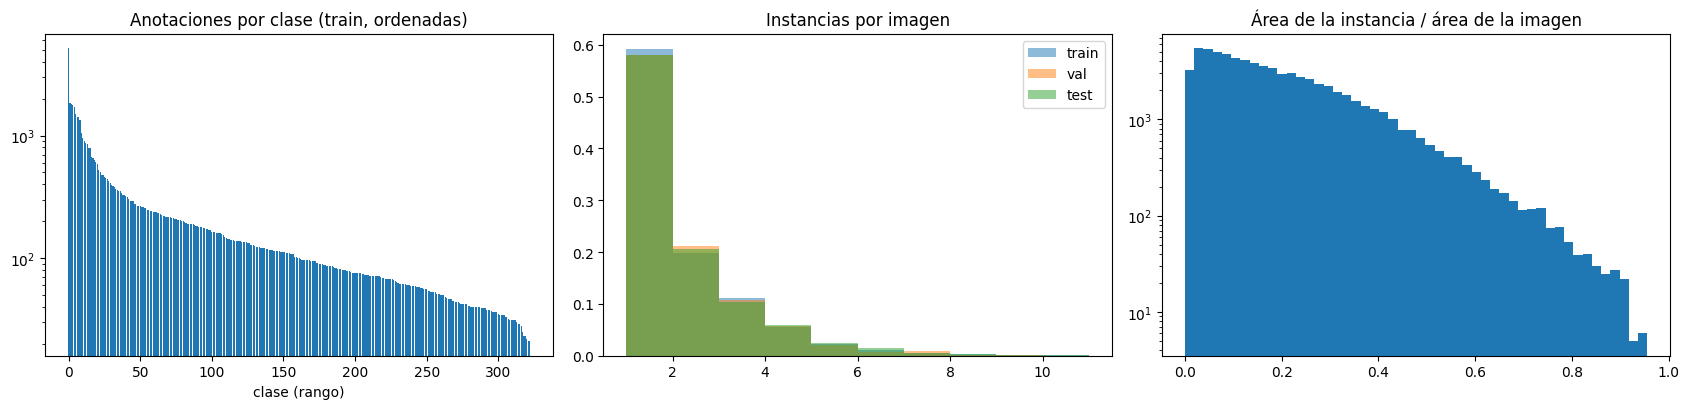

Top 8 clases (train):
cls
water                     5146
coffee                    1840
salad_leaf_salad_green    1825
bread_white               1787
tomato                    1718
butter                    1512
tea                       1423
carrot                    1408

8 clases más raras (train):
cls
cheesecake                                 29
banana_cake                                28
pie_apricot                                25
chocolate_egg_small                        23
aperitif_with_alcohol_n_s_aperol_spritz    23
lasagne_vegetable_prepared                 22
french_pizza_from_alsace_baked             21
damson_plum                                21

Clases con <5 anotaciones en val: 215 | en test: 43  (sus métricas por clase serán ruidosas: reportar intervalos)
Clases ausentes en val: 28 | en test: 0
Instancias iscrowd: 0 | con >1 polígono: 9,317


In [ ]:
rows = []
for s in ("train", "val", "test"):
    wh = {im["id"]: im["width"] * im["height"] for im in SPLIT_IMAGES[s]}
    for a in SPLIT_ANNS[s]:
        seg = a.get("segmentation")
        rows.append(dict(split=s, cls=a["class_idx"], image=a["image_id"], crowd=a.get("iscrowd", 0),
                         area_frac=(a.get("area") or 0) / max(1, wh[a["image_id"]]),
                         n_poly=len(seg) if isinstance(seg, list) else 0))
df = pd.DataFrame(rows)
names = {c["idx"]: c["name"] for c in CLASSES}

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
cnt_tr = df[df.split == "train"].cls.value_counts()
ax[0].bar(range(len(cnt_tr)), cnt_tr.values); ax[0].set_yscale("log")
ax[0].set_title("Anotaciones por clase (train, ordenadas)"); ax[0].set_xlabel("clase (rango)")
for s in ("train", "val", "test"):
    ax[1].hist(df[df.split == s].groupby("image").size(), bins=range(1, 12), alpha=.5, density=True, label=s)
ax[1].set_title("Instancias por imagen"); ax[1].legend()
ax[2].hist(df.area_frac.clip(0, 1), bins=50, log=True); ax[2].set_title("Área de la instancia / área de la imagen")
plt.tight_layout(); plt.savefig(OUT / "eda.png", dpi=110); plt.show()

print("Top 8 clases (train):");   print(cnt_tr.head(8).rename(index=names).to_string())
print("\n8 clases más raras (train):"); print(cnt_tr.tail(8).rename(index=names).to_string())
tab = df.pivot_table(index="cls", columns="split", values="image", aggfunc="count", fill_value=0).reindex(range(K), fill_value=0)
for s in ("train", "val", "test"):
    if s not in tab: tab[s] = 0
print(f"\nClases con <5 anotaciones en val: {(tab['val'] < 5).sum()} | en test: {(tab['test'] < 5).sum()}  "
      "(sus métricas por clase serán ruidosas: reportar intervalos)")
print(f"Clases ausentes en val: {(tab['val'] == 0).sum()} | en test: {(tab['test'] == 0).sum()}")
print(f"Instancias iscrowd: {int(df.crowd.sum()):,} | con >1 polígono: {(df.n_poly > 1).sum():,}")
tab.rename(index=names).to_csv(OUT / "class_counts_by_split.csv")

## 7. Geometría y recortes para los clasificadores (C1–C4)

**7.1 Diagnóstico.** Antes de recortar se mide (sin cargar imágenes) cuánto coincide la caja guardada con la caja del polígono, cuánto de su caja llena la máscara y qué tan pequeñas son las instancias. Además se comprueba en una muestra si el tamaño real de las fotos coincide con el que dice el COCO (orientación EXIF, reescalado): si no coincide, las cajas caen en el sitio equivocado.

Instancias con polígono: 75,146
  caja guardada vs caja del polígono: IoU<0.8 en 86.2 %  (IoU<0.5 en 47.2 %)
  relleno de la caja (área máscara / área caja) percentiles 5/25/50/75: [0.24 0.55 0.69 0.77]
  relleno <0.10: 0.9 % | área <1024 px: 0.3 %

Tamaño real de la foto vs tamaño del COCO (muestra): {'ok': 600}


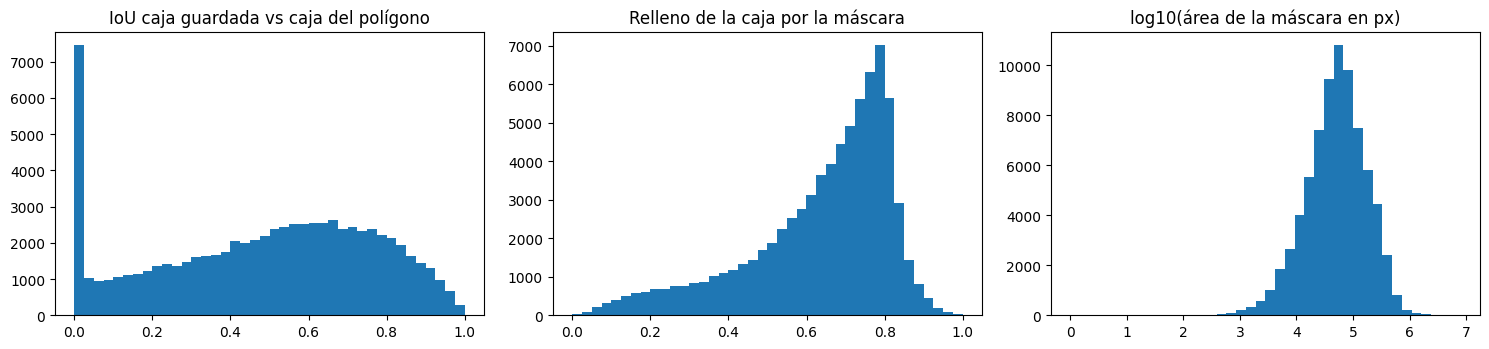

In [ ]:
from PIL import ImageOps

def mask_bbox(seg):
    if isinstance(seg, list) and seg:
        xs = [v for p in seg for v in p[0::2]]; ys = [v for p in seg for v in p[1::2]]
        if xs: return [min(xs), min(ys), max(xs) - min(xs), max(ys) - min(ys)]
    return None

def iou_xywh(a, b):
    ax1, ay1, bx1, by1 = a[0], a[1], b[0], b[1]
    iw = max(0, min(a[0] + a[2], b[0] + b[2]) - max(a[0], b[0])); ih = max(0, min(a[1] + a[3], b[1] + b[3]) - max(a[1], b[1]))
    inter = iw * ih; u = a[2] * a[3] + b[2] * b[3] - inter
    return inter / u if u > 0 else 0.0

def orient(path, info):
    # Devuelve (imagen, modo). Modo 'ok' | 'exif' (se aplicó la rotación EXIF) | 'scaled' | 'swapped'
    im = Image.open(path); tw, th = info["width"], info["height"]
    if im.size == (tw, th): return im, "ok"
    t = ImageOps.exif_transpose(im)
    if t.size == (tw, th): return t, "exif"
    if im.size == (th, tw): return im, "swapped"
    return im, "scaled"

geo = []
for s in ("train", "val", "test"):
    for a in SPLIT_ANNS[s]:
        mb = mask_bbox(a.get("segmentation"))
        if mb is None or a.get("iscrowd", 0): continue
        geo.append(dict(split=s, ann=a["id"], bbox_iou=iou_xywh(a["bbox"], mb),
                        fill=min(1.0, (a.get("area") or 0) / max(1.0, mb[2] * mb[3])), area=a.get("area") or 0))
geo = pd.DataFrame(geo)
print(f"Instancias con polígono: {len(geo):,}")
print(f"  caja guardada vs caja del polígono: IoU<0.8 en {100*(geo.bbox_iou<0.8).mean():.1f} %  (IoU<0.5 en {100*(geo.bbox_iou<0.5).mean():.1f} %)")
print("  relleno de la caja (área máscara / área caja) percentiles 5/25/50/75:",
      np.round(geo.fill.quantile([.05, .25, .5, .75]).values, 2))
print(f"  relleno <0.10: {100*(geo.fill<0.10).mean():.1f} % | área <1024 px: {100*(geo.area<1024).mean():.1f} %")

modes = Counter()
for s in ("train", "val"):
    for im in random.sample(SPLIT_IMAGES[s], min(300, len(SPLIT_IMAGES[s]))):
        try: modes[orient(IMG_DIR[im["dir"]] / im["file_name"], im)[1]] += 1
        except Exception: modes["error"] += 1
print("\nTamaño real de la foto vs tamaño del COCO (muestra):", dict(modes))
if modes.get("exif") or modes.get("scaled") or modes.get("swapped"):
    print("⚠️ Hay fotos cuyo tamaño no coincide con el COCO: el recorte las corrige (EXIF/escala) o las omite ('swapped').")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(geo.bbox_iou, bins=40); ax[0].set_title("IoU caja guardada vs caja del polígono")
ax[1].hist(geo.fill, bins=40); ax[1].set_title("Relleno de la caja por la máscara")
ax[2].hist(np.log10(geo.area.clip(1)), bins=40); ax[2].set_title("log10(área de la máscara en px)")
plt.tight_layout(); plt.show()

**7.2 Refinamiento de máscaras con SAM 2 y recorte.** Para cada instancia (no `iscrowd`) se hace lo siguiente, **antes** de aplicar ningún filtro de tamaño:

1. **Prompt.** Caja del polígono + un punto positivo en su zona más interna (máximo de la transformada de distancia) + hasta 3 puntos negativos tomados de las instancias vecinas que caen dentro de la caja (evita que la máscara se desborde al alimento de al lado).
2. **Selección.** SAM 2 propone 3 máscaras (limitadas a la caja ampliada un 15 %). Se descartan las que no coinciden con la anotación (`IoU < sam2_min_iou`) y, **entre las restantes, se elige la de mayor puntuación de SAM 2**. Así el polígono solo *valida*; si se eligiera la máscara más parecida al polígono, una anotación tosca arrastraría la máscara refinada hacia su propio error.
3. **Control de calidad.** Se acepta si la máscara elegida tiene `score ≥ sam2_min_score` (y, por construcción, `IoU ≥ sam2_min_iou`). Si no, se aplica `sam2_fallback`: queda el polígono original (la fila lo marca en `mask_src` y `fallback`) o se descarta. Las máscaras aceptadas se limpian (islas pequeñas fuera, huecos pequeños rellenos).
4. **Filtros.** Solo ahora se aplican `crop_min_side`, `crop_min_area_px` y `crop_min_fill`, sobre la máscara refinada.
5. **Salida.** `crops/` = recorte con **fondo negro** (caja ajustada a la máscara, borde erosionado 1 px) y `crops_ctx/` = el mismo alimento con su fondo original y margen del 10 %. Ambos comparten ruta relativa (`path`, `path_ctx` en el CSV) y se pueden comparar como ablación en C1–C4. Los polígonos refinados se guardan aparte en `refined_polys_{split}.json` (solo las instancias aceptadas por SAM 2); los `coco_*.json` **no cambian**, así que A y B no se ven afectados.

> **Colab: por lotes, con Drive y recuperación.** El trabajo se divide en lotes de `batch_images` fotos y cada lote se guarda en `drive_dir`. Para **pausar** de forma limpia usa `max_batches` o `time_budget_min` (al alcanzarlo la celda 7.2d se detiene con un aviso y *no* da el dataset por terminado). Para **recuperar** tras una desconexión: reconecta, ejecuta desde el principio hasta 7.2d (las secciones 1–6 son deterministas con la misma `seed`, así que reproducen las mismas particiones) y la celda reconstruye `crops/` desde los shards de Drive y continúa. Si cambias algún parámetro de recorte o de SAM 2, la configuración cambia y se empieza de cero (el progreso anterior queda en Drive sin tocar).

> **Requisitos:** GPU y, la primera vez, internet (para instalar `sam2` y bajar el checkpoint). Sin GPU, `use_sam2` se apaga solo y se usa el polígono original con fondo negro. **Recomendado:** primero ejecuta con `sam2_test_images = 200` y revisa 7.4; luego pon `None`. El progreso se guarda por foto, así que si la sesión se corta, volver a ejecutar esta sección **reanuda** donde quedó.

**7.2a Google Drive (Colab): progreso por lotes.** Cada lote de `batch_images` fotos se guarda en Drive como un *shard* (zip con los recortes del lote + sus registros). Si Colab se desconecta, vuelve a ejecutar el cuadernillo hasta 7.2d: lo ya hecho se recupera de Drive y solo se rehace el lote que estaba en curso.

In [ ]:
import zipfile, shutil, time
try:
    from google.colab import drive as _gdrive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

class Pausa(Exception):
    """Parada controlada (límite de lotes/tiempo): detiene 'Ejecutar todo' sin marcar el dataset como terminado."""
    def _render_traceback_(self): return [str(self)]

RUN = dict(t0=time.time(), batches=0)
DRIVE = None
if CFG["make_crops"] and CFG["drive_sync"]:
    if not IN_COLAB:
        print("ℹ️ No estás en Colab: drive_sync se ignora (el progreso queda en la carpeta de salida local).")
    else:
        if not Path("/content/drive/MyDrive").exists(): _gdrive.mount("/content/drive")
        if not Path("/content/drive/MyDrive").exists():
            raise RuntimeError("No se pudo montar Google Drive. Acepta el permiso del cuadro emergente o pon CFG['drive_sync']=False.")
        DRIVE = Path(CFG["drive_dir"]); (DRIVE / "_ckpt" / "shards").mkdir(parents=True, exist_ok=True)
        print("Progreso y resultados se guardan en Drive:", DRIVE)

def _atomic_copy(src, dst):
    tmp = Path(str(dst) + ".tmp"); shutil.copyfile(src, tmp); os.replace(tmp, dst)   # nunca queda un archivo a medias

def drive_push(s, h, recs):
    """Un lote -> un zip autocontenido en Drive: los JPEG del lote + records.jsonl con sus registros."""
    tmp = Path("/tmp/_shard.zip")
    with zipfile.ZipFile(tmp, "w", zipfile.ZIP_STORED) as z:          # los JPEG ya están comprimidos
        for r in recs:
            for row in r["rows"]:
                for rel in (row["path"], row["path_ctx"]):
                    if rel and (OUT / rel).exists(): z.write(OUT / rel, rel)
        z.writestr("records.jsonl", "\n".join(json.dumps(r) for r in recs))
    _atomic_copy(tmp, DRIVE / "_ckpt" / "shards" / f"{s}_{h}_{time.time_ns()}.zip"); tmp.unlink()

def drive_restore(s, h, part):
    """Sesión nueva: reconstruye el progreso local (jsonl + recortes) desde los shards de Drive."""
    shards = sorted((DRIVE / "_ckpt" / "shards").glob(f"{s}_{h}_*.zip"))
    lines, n_files = [], 0
    for sh in shards:
        try:
            with zipfile.ZipFile(sh) as z:
                names = z.namelist()
                if "records.jsonl" not in names: continue
                for m in names:
                    if m != "records.jsonl" and not (OUT / m).exists(): z.extract(m, OUT); n_files += 1
                lines += [l for l in z.read("records.jsonl").decode("utf-8").splitlines() if l.strip()]
        except zipfile.BadZipFile:
            print(f"   ⚠️ shard corrupto ignorado (sus fotos se reprocesarán): {sh.name}")
    part.parent.mkdir(exist_ok=True); part.write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
    other = {p.name.split("_")[1] for p in (DRIVE / "_ckpt" / "shards").glob(f"{s}_*.zip")} - {h}
    print(f"[{s}] recuperado desde Drive: {len(lines):,} fotos, {n_files:,} recortes en {len(shards)} shards" +
          (f" (ℹ️ en Drive hay progreso de {len(other)} configuración(es) distinta(s); no se usa ni se borra)" if other else ""))

def drive_save_finals():
    """Copia a Drive los resultados pequeños (JSON/CSV) para no depender de la sesión."""
    if DRIVE is None: return
    (DRIVE / "final").mkdir(exist_ok=True)
    for p in list(OUT.glob("*.json")) + list(OUT.glob("*.csv")): _atomic_copy(p, DRIVE / "final" / p.name)
    print("Resultados pequeños copiados a", DRIVE / "final")

Mounted at /content/drive
Progreso y resultados se guardan en Drive: /content/drive/MyDrive/food_prep_ckpt


**7.2b Cargar SAM 2.**

In [ ]:
import importlib, contextlib
try:
    import cv2
except ImportError:
    os.system(f"{sys.executable} -m pip install -q opencv-python-headless"); import cv2

PRED, DEVICE = None, "cpu"
if CFG["make_crops"] and CFG["use_sam2"]:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    if DEVICE == "cpu" and not CFG["sam2_allow_cpu"]:
        print("⚠️ No hay GPU: SAM 2 en CPU sería inviable con ~40 000 fotos. Se pone CFG['use_sam2']=False "
              "(los recortes usarán el polígono original sobre fondo negro). Activa la GPU o pon sam2_allow_cpu=True.")
        CFG["use_sam2"] = False

if CFG["make_crops"] and CFG["use_sam2"]:
    try:
        import sam2
    except ImportError:
        print("Instalando SAM 2 (requiere internet)…")
        os.system(f"{sys.executable} -m pip install -q hydra-core iopath huggingface_hub")
        os.system(f"{sys.executable} -m pip install -q --no-deps git+https://github.com/facebookresearch/sam2.git")
        importlib.invalidate_caches()
    try:
        from sam2.sam2_image_predictor import SAM2ImagePredictor
        if CFG["sam2_ckpt"]:            # modo sin internet: config + checkpoint locales
            from sam2.build_sam import build_sam2
            PRED = SAM2ImagePredictor(build_sam2(CFG["sam2_cfg"], CFG["sam2_ckpt"], device=DEVICE))
        else:                           # descarga el checkpoint desde Hugging Face
            PRED = SAM2ImagePredictor.from_pretrained(CFG["sam2_model_id"], device=DEVICE)
    except Exception as e:
        raise RuntimeError(f"No se pudo cargar SAM 2 ({type(e).__name__}: {e}). Activa internet, o define "
                           "CFG['sam2_cfg'] y CFG['sam2_ckpt'] con archivos locales, o pon CFG['use_sam2']=False.") from e
    print(f"SAM 2 listo: {CFG['sam2_ckpt'] or CFG['sam2_model_id']} en {DEVICE}")
else:
    print("SAM 2 desactivado: se usará el polígono original como máscara." if CFG["make_crops"] else "Recortes desactivados.")

⚠️ No hay GPU: SAM 2 en CPU sería inviable con ~40 000 fotos. Se pone CFG['use_sam2']=False (los recortes usarán el polígono original sobre fondo negro). Activa la GPU o pon sam2_allow_cpu=True.
SAM 2 desactivado: se usará el polígono original como máscara.


**7.2c Funciones de refinamiento y recorte.**

In [ ]:
from collections import deque

BGC = tuple(int(v) for v in CFG["bg_color"])

# ---------- utilidades de máscara (todas trabajan en el "espacio de trabajo": foto reducida a sam2_max_side) ----------
def poly_raster(seg, kx, ky, ox, oy, w, h):
    m = Image.new("L", (w, h), 0); d = ImageDraw.Draw(m)
    for poly in (seg or []):
        if isinstance(poly, list) and len(poly) >= 6:
            d.polygon([(poly[i] * kx - ox, poly[i + 1] * ky - oy) for i in range(0, len(poly) - 1, 2)], fill=255)
    return np.asarray(m) > 0

def rect_mask(bx, ox, oy, w, h):
    m = np.zeros((h, w), bool)
    x0, y0 = max(0, int(round(bx[0] - ox))), max(0, int(round(bx[1] - oy)))
    x1, y1 = min(w, int(round(bx[0] + bx[2] - ox))), min(h, int(round(bx[1] + bx[3] - oy)))
    m[y0:y1, x0:x1] = True
    return m

def interior_point(m):
    """Punto más interno de la máscara (máximo de la transformada de distancia) -> (x, y) local, o None."""
    if not m.any(): return None
    dt = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 3)
    y, x = np.unravel_index(int(dt.argmax()), dt.shape)
    return float(x), float(y)

def region(bx, W, H, expand):
    x, y, w, h = bx; ex, ey = w * expand, h * expand
    return (max(0, int(np.floor(x - ex))), max(0, int(np.floor(y - ey))),
            min(W, int(np.ceil(x + w + ex))), min(H, int(np.ceil(y + h + ey))))

def clean_mask(m, comp_min_frac, hole_max_frac):
    """Quita islas pequeñas (< comp_min_frac del componente mayor) y rellena huecos internos pequeños."""
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8)
    if n <= 1: return m
    areas = stats[1:, cv2.CC_STAT_AREA]
    m2 = np.isin(lab, 1 + np.where(areas >= comp_min_frac * areas.max())[0])
    n2, lab2, st2, _ = cv2.connectedComponentsWithStats((~m2).astype(np.uint8), connectivity=4)
    total, (h, w) = int(m2.sum()), m2.shape
    for i in range(1, n2):
        x, y, ww, hh, a = st2[i]
        if x > 0 and y > 0 and x + ww < w and y + hh < h and a <= hole_max_frac * total:   # hueco que no toca el borde
            m2[lab2 == i] = True
    return m2

def mask_to_polys(m, rx0, ry0, kx, ky, eps=1.0):
    """Máscara local -> polígonos en coordenadas COCO (solo contornos externos, simplificados)."""
    cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = []
    for c in cs:
        if cv2.contourArea(c) < 4: continue
        c = cv2.approxPolyDP(c, eps * (kx + ky) / 2, True).reshape(-1, 2)
        if len(c) < 3: continue
        out.append([round(float(v), 1) for p in c for v in ((p[0] + rx0) / kx, (p[1] + ry0) / ky)])
    return out

def mask_for_box(m, rx0, ry0, ws, box):
    """Lleva la máscara local (espacio de trabajo) a la resolución de la foto real, recortada a `box` (x0,y0,x1,y1)."""
    X0, Y0, X1, Y1 = box
    M = np.array([[ws, 0, ws * X0 - rx0], [0, ws, ws * Y0 - ry0]], dtype=np.float32)
    out = cv2.warpAffine(m.astype(np.uint8) * 255, M, (X1 - X0, Y1 - Y0),
                         flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP, borderValue=0)
    return out > 127

def _fit_size(w, h):
    s = min(1.0, CFG["crop_max_side"] / max(w, h))
    return max(1, round(w * s)), max(1, round(h * s))

def _write_pair(sub_c, p_c, sub_m, mask_m, p_m):
    """Se ejecuta en hilos de escritura: reduce, aplica el fondo negro y guarda los JPEG."""
    if sub_c is not None:
        sz = _fit_size(*sub_c.size)
        if sz != sub_c.size: sub_c = sub_c.resize(sz, Image.LANCZOS)
        p_c.parent.mkdir(parents=True, exist_ok=True); sub_c.save(p_c, quality=92)
    sz = _fit_size(*sub_m.size)
    mk = mask_m
    if sz != sub_m.size:
        sub_m = sub_m.resize(sz, Image.LANCZOS)
        mk = cv2.resize(mask_m.astype(np.uint8) * 255, sz, interpolation=cv2.INTER_AREA) > 127
    er = int(CFG["mask_erode_px"])
    if er > 0:                                         # quita el halo del fondo original en el borde
        e = cv2.erode(mk.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * er + 1, 2 * er + 1))) > 0
        if e.any(): mk = e
    arr = np.array(sub_m); arr[~mk] = BGC
    p_m.parent.mkdir(parents=True, exist_ok=True); Image.fromarray(arr).save(p_m, quality=95)

def _sam_ctx():
    st = contextlib.ExitStack()
    if CFG["use_sam2"]:
        st.enter_context(torch.inference_mode())
        dt = CFG["sam2_dtype"]
        if dt == "auto": dt = "bf16" if (DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8) else "fp32"   # T4 no tiene bf16 real: fp32 es lo seguro
        if DEVICE == "cuda" and dt != "fp32":
            st.enter_context(torch.autocast("cuda", dtype=torch.bfloat16 if dt == "bf16" else torch.float16))
    return st

# ---------- SAM 2 sobre una instancia ----------
def sam_refine(it, items):
    """Devuelve dict(ok, mask, score, iou, why). Las máscaras viven en la ventana local it['reg']."""
    rx0, ry0, rx1, ry1 = it["reg"]; pm = it["pm"]
    if it["ip"] is None: return dict(ok=False, why="sin_punto")
    bx = it["bx"]; box = (bx[0], bx[1], bx[0] + bx[2], bx[1] + bx[3])
    pos = (it["ip"][0] + rx0, it["ip"][1] + ry0)
    negs = []                                          # puntos negativos: centros de las instancias vecinas dentro de la caja
    for o in items:
        if o is it or o["ip"] is None: continue
        px, py = o["ip"][0] + o["reg"][0], o["ip"][1] + o["reg"][1]
        if not (box[0] <= px <= box[2] and box[1] <= py <= box[3]): continue
        lx, ly = int(round(px - rx0)), int(round(py - ry0))
        if 0 <= ly < pm.shape[0] and 0 <= lx < pm.shape[1] and pm[ly, lx]: continue   # cae dentro de esta instancia
        negs.append((px, py))
    negs = negs[:CFG["sam2_max_neg"]]
    try:
        masks, scores, _ = PRED.predict(
            point_coords=np.array([pos] + negs, dtype=np.float32),
            point_labels=np.array([1] + [0] * len(negs), dtype=np.int32),
            box=np.array(box, dtype=np.float32), multimask_output=True, return_logits=False)
    except Exception as e:
        return dict(ok=False, why="sam2_error:" + type(e).__name__)
    masks = np.asarray(masks); scores = np.atleast_1d(np.asarray(scores))
    if masks.ndim == 2: masks = masks[None]
    cm = masks[:, ry0:ry1, rx0:rx1] > 0.5              # se limita a la ventana (evita fugas a toda la foto)
    ious = (cm & pm).sum((1, 2)) / np.maximum((cm | pm).sum((1, 2)), 1)
    ok_c = np.where(ious >= CFG["sam2_min_iou"])[0]    # candidatos coherentes con la anotación...
    k = int(ok_c[np.argmax(scores[ok_c] + 1e-3 * ious[ok_c])]) if len(ok_c) else int(np.argmax(ious))   # ...y entre ellos manda SAM 2 (no el polígono)
    iou, score = float(ious[k]), float(scores[k])
    why = "score_bajo" if score < CFG["sam2_min_score"] else ("iou_bajo" if iou < CFG["sam2_min_iou"] else None)
    if why: return dict(ok=False, why=why, score=score, iou=iou)
    m = clean_mask(cm[k], CFG["sam2_comp_min_frac"], CFG["sam2_hole_max_frac"])
    if not m.any(): return dict(ok=False, why="vacia", score=score, iou=iou)
    return dict(ok=True, mask=m, score=score, iou=iou)

# ---------- una foto completa ----------
def process_loaded(split, info, anns, im, mode, writer, futs):
    rec = dict(image_id=info["id"], rows=[], polys={}, reasons=Counter(), ex=[], fail=None)
    W, H = im.size; tw, th = info["width"], info["height"]; sx, sy = W / tw, H / th
    if mode == "swapped":
        rec["reasons"]["geom_swapped"] += len(anns); return rec
    ws = min(1.0, CFG["sam2_max_side"] / max(W, H)) if CFG["use_sam2"] else 1.0
    kx, ky = sx * ws, sy * ws                           # COCO -> espacio de trabajo
    Wk, Hk = max(1, round(W * ws)), max(1, round(H * ws))

    items = []
    for a in anns:
        if a.get("iscrowd", 0): rec["reasons"]["crowd"] += 1; continue
        seg = a.get("segmentation"); mb = mask_bbox(seg)
        x, y, w, h = mb if (mb and CFG["bbox_source"] == "mask") else a["bbox"]
        bx = (x * kx, y * ky, w * kx, h * ky)
        if min(bx[2], bx[3]) / ws < CFG["sam2_min_prompt_side"]:        # solo descarta cajas degeneradas (prompt imposible)
            rec["reasons"]["lado_pequeño"] += 1; continue
        reg = region(bx, Wk, Hk, CFG["sam2_box_expand"])
        rw, rh = reg[2] - reg[0], reg[3] - reg[1]
        if rw < 2 or rh < 2: rec["reasons"]["fuera_de_imagen"] += 1; continue
        pm = poly_raster(seg, kx, ky, reg[0], reg[1], rw, rh) if (isinstance(seg, list) and seg) else None
        psrc = "polygon"
        if pm is None or not pm.any(): pm, psrc = rect_mask(bx, reg[0], reg[1], rw, rh), "bbox"
        items.append(dict(a=a, bx=bx, reg=reg, pm=pm, psrc=psrc, ip=interior_point(pm),
                          biou=iou_xywh(a["bbox"], mb) if mb else 1.0))

    if CFG["use_sam2"] and items:
        wim = im if ws == 1.0 else im.resize((Wk, Hk), Image.BILINEAR)
        try:
            with _sam_ctx():
                PRED.set_image(np.asarray(wim))
                for it in items: it["sam"] = sam_refine(it, items)
        except Exception as e:
            for it in items: it["sam"] = dict(ok=False, why="sam2_error:" + type(e).__name__)

    for it in items:
        a, (rx0, ry0, rx1, ry1), sam = it["a"], it["reg"], it.get("sam")
        if sam is not None and sam["ok"]:
            m, src, why = sam["mask"], "sam2", ""
        else:
            why = sam["why"] if sam is not None else ""
            if sam is not None and CFG["sam2_fallback"] == "drop":
                rec["reasons"]["sam2_" + why] += 1; rec["ex"].append([a["id"], "sam2_" + why]); continue
            m, src = it["pm"], it["psrc"]
        if why: rec["reasons"]["fallback_" + why] += 1

        ys, xs = np.nonzero(m)
        if xs.size == 0: rec["reasons"]["mascara_vacia"] += 1; continue
        area_w, bw, bh = int(xs.size), int(xs.max() - xs.min() + 1), int(ys.max() - ys.min() + 1)
        tx0, ty0 = (rx0 + xs.min()) / ws, (ry0 + ys.min()) / ws       # caja ajustada a la máscara, en px de la foto real
        tx1, ty1 = tx0 + bw / ws, ty0 + bh / ws
        area_px, fill = area_w / ws ** 2, area_w / max(1, bw * bh)

        # >>> filtros de tamaño: ahora se aplican sobre la máscara REFINADA <<<
        if min(tx1 - tx0, ty1 - ty0) < CFG["crop_min_side"]: rec["reasons"]["lado_pequeño"] += 1; rec["ex"].append([a["id"], "lado_pequeño"]); continue
        if area_px < CFG["crop_min_area_px"]: rec["reasons"]["área_pequeña"] += 1; rec["ex"].append([a["id"], "área_pequeña"]); continue
        if fill < CFG["crop_min_fill"]: rec["reasons"]["relleno_bajo"] += 1; rec["ex"].append([a["id"], "relleno_bajo"]); continue

        def box_with(mg):
            mx, my = (tx1 - tx0) * mg, (ty1 - ty0) * mg
            return (max(0, int(tx0 - mx)), max(0, int(ty0 - my)), min(W, int(np.ceil(tx1 + mx))), min(H, int(np.ceil(ty1 + my))))
        box_m = box_with(CFG["crop_margin_masked"])
        if box_m[2] - box_m[0] < 2 or box_m[3] - box_m[1] < 2: rec["reasons"]["fuera_de_imagen"] += 1; continue
        sub_m = im.crop(box_m); mk = mask_for_box(m, rx0, ry0, ws, box_m)
        sub_c = im.crop(box_with(CFG["crop_margin"])) if CFG["save_context"] else None
        rel_m = Path("crops") / split / f"{a['class_idx']:03d}" / f"{a['id']}.jpg"
        rel_c = Path("crops_ctx") / split / f"{a['class_idx']:03d}" / f"{a['id']}.jpg"
        futs.append(writer.submit(_write_pair, sub_c, OUT / rel_c, sub_m, mk, OUT / rel_m))

        cw, ch = _fit_size(*sub_m.size)
        rec["rows"].append(dict(
            split=split, ann_id=int(a["id"]), image_id=int(a["image_id"]), class_idx=int(a["class_idx"]),
            path=str(rel_m), path_ctx=str(rel_c) if CFG["save_context"] else "", crop_w=cw, crop_h=ch,
            fill=round(float(fill), 3), bbox_iou=round(float(it["biou"]), 3), area_frac=round(area_w / (Wk * Hk), 5),
            mask_src=src, sam_score=None if sam is None or "score" not in sam else round(sam["score"], 3),
            sam_iou=None if sam is None or "iou" not in sam else round(sam["iou"], 3),
            area_ratio=round(area_w / max(1, int(it["pm"].sum())), 3), fallback=why, geom=mode))
        if src == "sam2" and CFG["save_refined_polys"]:
            rec["polys"][str(a["id"])] = dict(
                segmentation=mask_to_polys(m, rx0, ry0, kx, ky), area=round(area_w / (kx * ky), 1),
                bbox=[round((rx0 + xs.min()) / kx, 1), round((ry0 + ys.min()) / ky, 1), round(bw / kx, 1), round(bh / ky, 1)])
        rec["reasons"]["ok"] += 1
    return rec

def load_image(task):
    s, info, anns = task
    p = IMG_DIR[info["dir"]] / info["file_name"]
    try:
        im, mode = orient(p, info); return task, im.convert("RGB"), mode
    except Exception as e:
        return task, None, f"{p} ({type(e).__name__})"

def prefetch(seq, fn, workers, window):
    """Carga imágenes en hilos con una ventana acotada (no llena la RAM) y las entrega en orden."""
    with ThreadPoolExecutor(workers) as ex:
        q, i = deque(), 0
        while i < len(seq) and len(q) < window: q.append(ex.submit(fn, seq[i])); i += 1
        while q:
            r = q.popleft().result()
            if i < len(seq): q.append(ex.submit(fn, seq[i])); i += 1
            yield r

**7.2d Ejecución por lotes.** Genera `crops/`, `crops_ctx/`, `crops_{split}.csv` y `refined_polys_{split}.json`.

In [ ]:
def _cfg_hash():
    skip = {"sam2_test_images", "sam2_allow_cpu", "sam2_dtype", "resume", "delete_partial_at_end", "n_workers", "out_dir", "data_root"}
    keys = [k for k in CFG if (k.startswith(("crop_", "sam2_", "mask_", "bg_", "bbox_", "save_")) or k == "use_sam2") and k not in skip]
    blob = json.dumps({k: CFG[k] for k in keys}, sort_keys=True, default=str) + json.dumps(SPLITS, sort_keys=True)
    return hashlib.sha256(blob.encode()).hexdigest()[:10]

def _must_stop():
    if CFG["max_batches"] and RUN["batches"] >= int(CFG["max_batches"]): return f"límite de {CFG['max_batches']} lotes alcanzado"
    if CFG["time_budget_min"] and (time.time() - RUN["t0"]) / 60 >= float(CFG["time_budget_min"]): return f"presupuesto de {CFG['time_budget_min']} min agotado"
    return None

def run_split(s, writer, h):
    """Devuelve (rows, polys, tot, fails, ex), o None si se paró antes de terminar la partición."""
    grp = defaultdict(list)
    for a in SPLIT_ANNS[s]: grp[a["image_id"]].append(a)
    imgs = SPLIT_IMAGES[s]
    if CFG["sam2_test_images"]:
        imgs = random.Random(CFG["seed"]).sample(imgs, min(int(CFG["sam2_test_images"]), len(imgs)))
    tasks = [(s, im, grp[im["id"]]) for im in imgs]

    part = OUT / "_partial" / f"{s}_{h}.jsonl"; part.parent.mkdir(exist_ok=True)
    for old in part.parent.glob(f"{s}_*.jsonl"):        # progreso local de OTRA configuración: sus JPEG ya fueron (o van a ser) sobrescritos
        if old != part: old.unlink()
    if CFG["resume"] and DRIVE is not None and (not part.exists() or part.stat().st_size == 0):
        drive_restore(s, h, part)                       # sesión nueva (o recortes perdidos): se recupera de Drive
    done = {}
    if CFG["resume"] and part.exists():
        for line in part.read_text(encoding="utf-8").splitlines():
            try: r = json.loads(line)
            except ValueError: continue                 # línea truncada por un corte
            done[r["image_id"]] = r
    todo = [t for t in tasks if t[1]["id"] not in done]
    if done: print(f"[{s}] reanudando: {len(done):,} fotos ya procesadas, faltan {len(todo):,}")

    pending, batch_recs = deque(), []                   # (registro, escrituras en curso); la línea solo se anota cuando sus JPEG ya existen
    def _commit(fp, upto):
        while len(pending) > upto:
            rec, fs = pending.popleft()
            for f in fs: f.result()
            fp.write(json.dumps(rec) + "\n"); done[rec["image_id"]] = rec; batch_recs.append(rec)
    BATCH = int(CFG["batch_images"] or 0) or max(1, len(todo))
    stop = None
    with part.open("w", encoding="utf-8") as fp:
        for r in done.values(): fp.write(json.dumps(r) + "\n")   # reescribe solo líneas válidas
        for b0 in range(0, len(todo), BATCH):
            stop = _must_stop()
            if stop: break
            chunk, batch_recs[:] = todo[b0:b0 + BATCH], []
            for task, im, mode in tqdm(prefetch(chunk, load_image, CFG["n_workers"], 2 * CFG["n_workers"]),
                                       total=len(chunk), desc=f"{s} lote {b0 // BATCH + 1}/{-(-len(todo) // BATCH)}"):
                info, fs = task[1], []
                if im is None: rec = dict(image_id=info["id"], rows=[], polys={}, reasons={}, ex=[], fail=str(mode))
                else:
                    rec = process_loaded(s, info, task[2], im, mode, writer, fs); rec["reasons"] = dict(rec["reasons"])
                pending.append((rec, fs)); _commit(fp, 2)
            _commit(fp, 0); fp.flush(); os.fsync(fp.fileno())
            if DRIVE is not None: drive_push(s, h, batch_recs)        # el lote queda a salvo en Drive
            RUN["batches"] += 1
    if stop:
        left = len([t for t in tasks if t[1]["id"] not in done])
        print(f"[{s}] ⏸️ parada controlada ({stop}); faltan {left:,} fotos.")
        return None

    rows, polys, tot, fails, ex = [], {}, Counter(), [], []
    for t in tasks:
        r = done[t[1]["id"]]
        rows += r["rows"]; polys.update(r["polys"]); tot.update(r["reasons"]); ex += r["ex"]
        if r["fail"]: fails.append(r["fail"])
    return rows, polys, tot, fails, ex

CROPS, DISCARDED = {}, []
if CFG["make_crops"]:
    H_CFG = _cfg_hash(); RUN.update(t0=time.time(), batches=0)
    if CFG["sam2_test_images"]:
        print(f"⚠️ MODO PRUEBA: solo {CFG['sam2_test_images']} fotos por partición. Pon CFG['sam2_test_images']=None para el dataset completo "
              "(lo ya procesado se reutiliza si no cambias la configuración).")
    with ThreadPoolExecutor(4) as writer:
        for s in ("train", "val", "test"):
            res = run_split(s, writer, H_CFG)
            if res is None:
                raise Pausa("⏸️ Procesamiento en pausa. El progreso está guardado" + (" en Drive" if DRIVE else " en _partial/") +
                            ". Vuelve a ejecutar esta celda (o 'Ejecutar todo') para continuar donde quedó.")
            rows, polys, tot, fails, ex = res
            CROPS[s] = pd.DataFrame(rows); CROPS[s].to_csv(OUT / f"crops_{s}.csv", index=False)
            if polys and CFG["save_refined_polys"]:
                json.dump(polys, open(OUT / f"refined_polys_{s}.json", "w"))
            if s == "train": DISCARDED = [tuple(e) for e in ex]
            print(f"[{s}] recortes: {len(rows):,} | imágenes ilegibles: {len(fails)} | motivos: {dict(tot)}")
            if len(rows): print("      origen de la máscara:", CROPS[s].mask_src.value_counts().to_dict())
            n_err = sum(v for k, v in tot.items() if "sam2_error" in k)
            if n_err: print(f"      ⚠️ {n_err} instancias con error de SAM 2 (cayeron al polígono): revisa la memoria de GPU / la instalación.")
    drive_save_finals()
else:
    print("Recortes desactivados (CFG['make_crops']=False).")

[train] recuperado desde Drive: 0 fotos, 0 recortes en 0 shards


train lote 1/71:   0%|          | 0/500 [00:00<?, ?it/s]

train lote 2/71:   0%|          | 0/500 [00:00<?, ?it/s]

train lote 3/71:   0%|          | 0/500 [00:00<?, ?it/s]

train lote 4/71:   0%|          | 0/500 [00:00<?, ?it/s]

train lote 5/71:   0%|          | 0/500 [00:00<?, ?it/s]

... (75 outputs left out)

test lote 6/8:   0%|          | 0/500 [00:00<?, ?it/s]

test lote 7/8:   0%|          | 0/500 [00:00<?, ?it/s]

test lote 8/8:   0%|          | 0/411 [00:00<?, ?it/s]

[test] recortes: 7,301 | imágenes ilegibles: 0 | motivos: {'ok': 7301, 'lado_pequeño': 19, 'relleno_bajo': 73, 'área_pequeña': 12}
      origen de la máscara: {'polygon': 7301}
Resultados pequeños copiados a /content/drive/MyDrive/food_prep_ckpt/final


**7.3 Revisión visual.** Se dibuja el polígono (verde) y la caja de recorte (rojo) sobre la foto completa. Fila de arriba: los recortes conservados con menor relleno. Fila de abajo: instancias descartadas (el motivo aparece en el título). Aquí se dibuja el polígono **original**; la comparación con la máscara de SAM 2 está en 7.4. Si el polígono no cubre el alimento, el problema está en la anotación; si lo cubre pero el recorte no, está en el código.

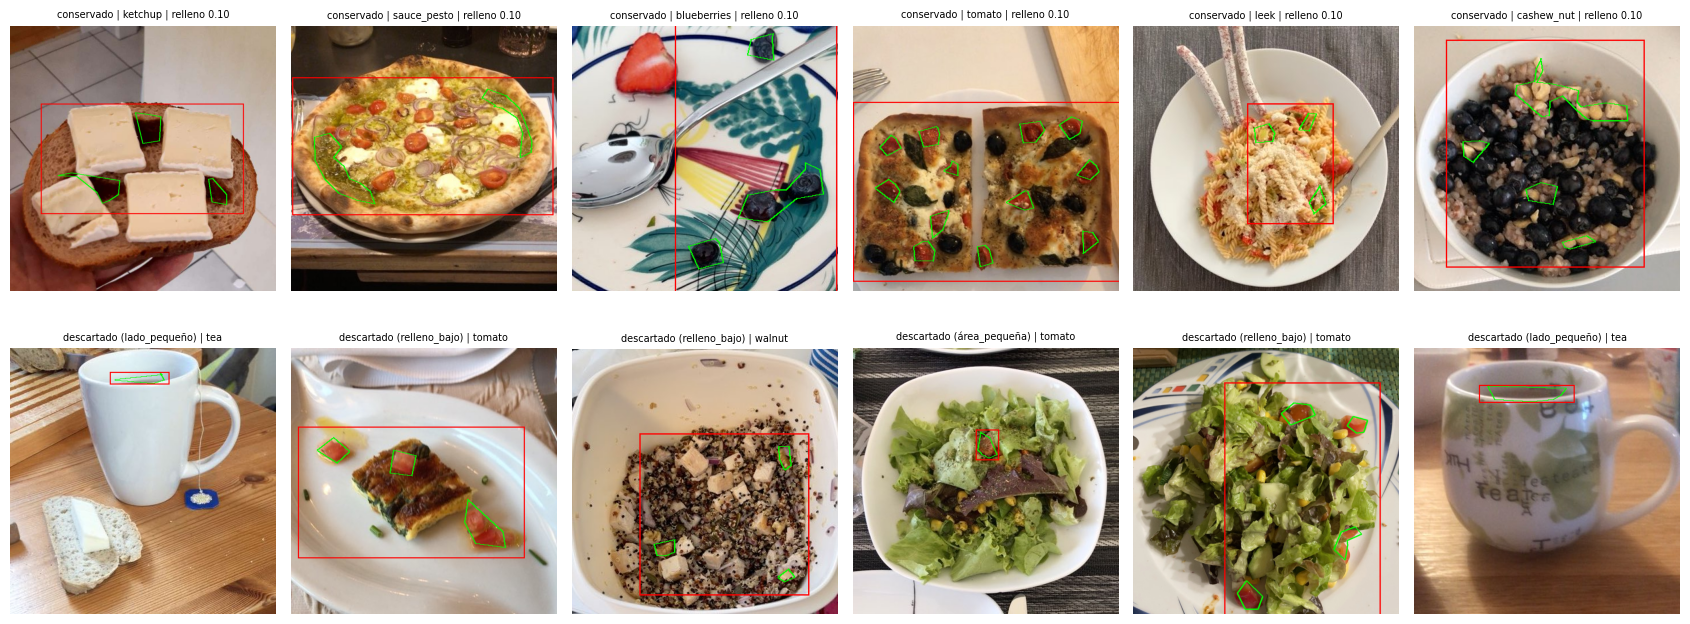

In [ ]:
def show_overlay(ax_, a, info, title):
    im, mode = orient(IMG_DIR[info["dir"]] / info["file_name"], info); im = im.convert("RGB")
    W, H = im.size; sx, sy = W / info["width"], H / info["height"]
    d = ImageDraw.Draw(im)
    for poly in (a.get("segmentation") or []):
        if isinstance(poly, list) and len(poly) >= 6:
            d.line([(poly[i] * sx, poly[i + 1] * sy) for i in range(0, len(poly) - 1, 2)] + [(poly[0] * sx, poly[1] * sy)], fill=(0, 255, 0), width=max(2, W // 200))
    mb = mask_bbox(a.get("segmentation")) or a["bbox"]
    x, y, w, h = mb[0] * sx, mb[1] * sy, mb[2] * sx, mb[3] * sy
    d.rectangle([x - w * CFG["crop_margin"], y - h * CFG["crop_margin"], x + w * (1 + CFG["crop_margin"]), y + h * (1 + CFG["crop_margin"])], outline=(255, 0, 0), width=max(2, W // 200))
    ax_.imshow(im); ax_.axis("off"); ax_.set_title(title, fontsize=7)

if CROPS.get("train") is not None and len(CROPS["train"]):
    A = {a["id"]: a for a in SPLIT_ANNS["train"]}; I = {im["id"]: im for im in SPLIT_IMAGES["train"]}
    low = CROPS["train"].sort_values("fill").head(6)
    disc = random.sample(DISCARDED, min(6, len(DISCARDED)))
    fig, axes = plt.subplots(2, 6, figsize=(17, 7))
    for ax_, (_, r) in zip(axes[0], low.iterrows()):
        show_overlay(ax_, A[r.ann_id], I[r.image_id], f"conservado | {names[r.class_idx][:20]} | relleno {r.fill:.2f}")
    for ax_, (aid, why) in zip(axes[1], disc):
        show_overlay(ax_, A[aid], I[A[aid]["image_id"]], f"descartado ({why}) | {names[A[aid]['class_idx']][:18]}")
    for ax_ in axes[1][len(disc):]: ax_.axis("off")
    plt.tight_layout(); plt.show()

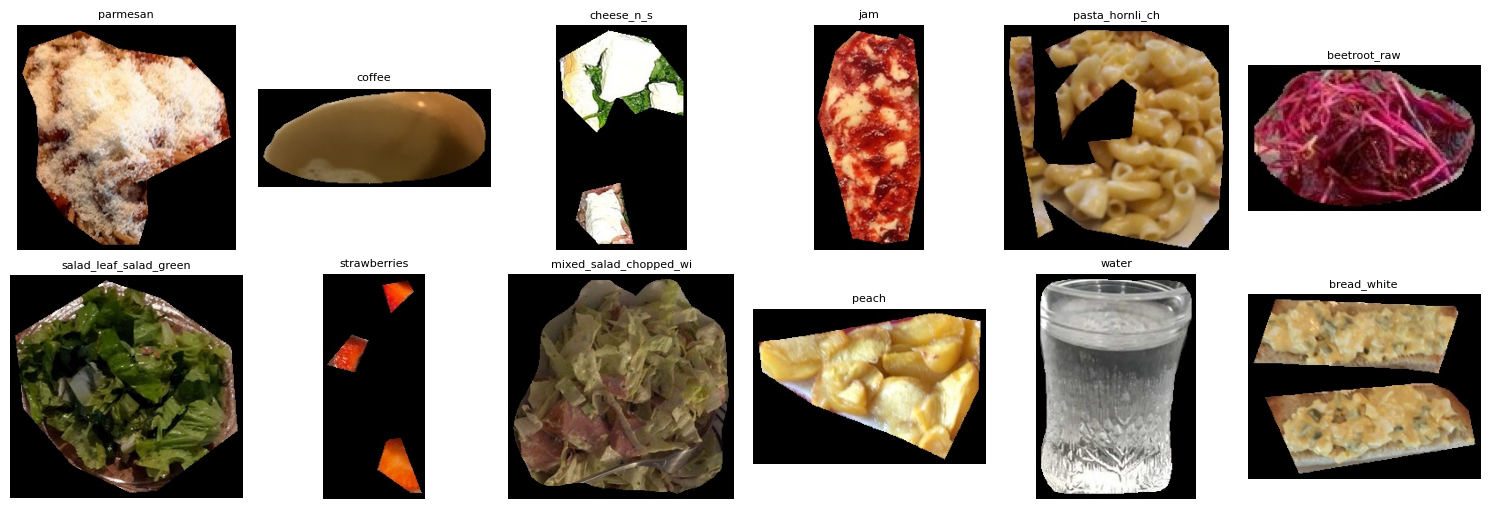

In [ ]:
# vista rápida de recortes (train) — fondo negro
if CROPS.get("train") is not None and len(CROPS["train"]):
    samp = CROPS["train"].sample(min(12, len(CROPS["train"])), random_state=0)
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
    for ax_, (_, r) in zip(axes.flat, samp.iterrows()):
        ax_.imshow(Image.open(OUT / r.path)); ax_.axis("off"); ax_.set_title(names[r.class_idx][:22], fontsize=8)
    plt.tight_layout(); plt.show()

**7.4 Calidad del refinamiento.** Cada celda muestra `[con contexto | fondo negro]`. Fila 1: muestra aleatoria. Fila 2: las máscaras de SAM 2 aceptadas con **menor** IoU frente al polígono (los casos límite: aquí se decide si `sam2_min_iou` está bien puesto). Fila 3: instancias donde SAM 2 se rechazó y se conservó el polígono original. Si en la fila 2 ves máscaras claramente peores que el polígono, sube `sam2_min_iou`/`sam2_min_score`; si en la fila 3 ves que SAM 2 tenía razón, bájalos.

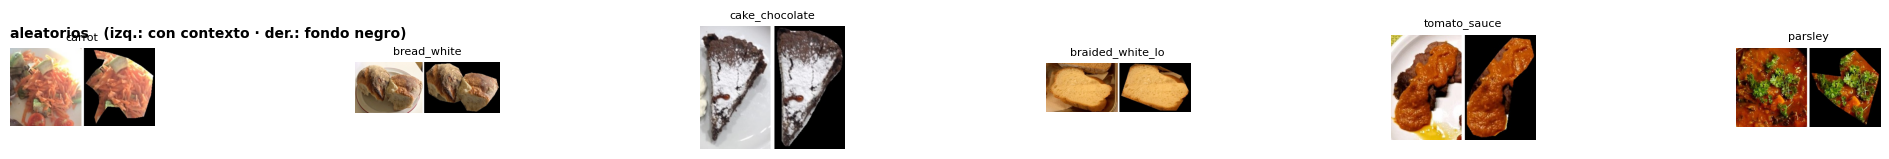

In [ ]:
def pair_img(r, h=190):
    """[contexto | fondo negro] lado a lado, a la misma altura."""
    ims = [Image.open(OUT / r.path).convert("RGB")]
    if isinstance(r.path_ctx, str) and r.path_ctx: ims.insert(0, Image.open(OUT / r.path_ctx).convert("RGB"))
    ims = [i.resize((max(1, round(i.width * h / i.height)), h)) for i in ims]
    canvas = Image.new("RGB", (sum(i.width for i in ims) + 6 * (len(ims) - 1), h), (255, 255, 255))
    x = 0
    for i in ims: canvas.paste(i, (x, 0)); x += i.width + 6
    return canvas

df_tr = CROPS.get("train")
if df_tr is not None and len(df_tr):
    groups = [("aleatorios", df_tr.sample(min(6, len(df_tr)), random_state=1))]
    if CFG["use_sam2"]:
        s2, fb = df_tr[df_tr.mask_src == "sam2"], df_tr[df_tr.mask_src != "sam2"]
        if len(s2): groups.append(("SAM 2 aceptados con menor IoU vs polígono", s2.nsmallest(6, "sam_iou")))
        if len(fb): groups.append(("fallback al polígono original", fb.sample(min(6, len(fb)), random_state=1)))
    fig, axes = plt.subplots(len(groups), 6, figsize=(19, 3.6 * len(groups)), squeeze=False)
    for row, (title, g) in zip(axes, groups):
        for ax_ in row: ax_.axis("off")
        for ax_, (_, r) in zip(row, g.iterrows()):
            ax_.imshow(pair_img(r))
            sc = "" if pd.isna(r.sam_iou) else f" | IoU {r.sam_iou:.2f}"
            ax_.set_title(f"{names[r.class_idx][:16]}{sc}", fontsize=8)
        row[0].text(0, 1.14, f"{title}   (izq.: con contexto · der.: fondo negro)", transform=row[0].transAxes, fontsize=10, weight="bold")
    plt.tight_layout(); plt.show()

    if CFG["use_sam2"]:
        print("Origen de la máscara:", df_tr.mask_src.value_counts().to_dict())
        print("Motivo de fallback:   ", df_tr[df_tr.fallback != ""].fallback.value_counts().to_dict())
        print(df_tr[df_tr.mask_src == "sam2"][["sam_score", "sam_iou", "area_ratio", "fill"]]
              .describe(percentiles=[.05, .25, .5, .75]).round(3).to_string())
        fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
        ax[0].hist(df_tr.sam_score.dropna(), bins=40); ax[0].set_title("puntuación predicha por SAM 2")
        ax[1].hist(df_tr.sam_iou.dropna(), bins=40);   ax[1].set_title("IoU máscara SAM 2 vs polígono original")
        ax[2].hist(df_tr.area_ratio.clip(0, 3), bins=40); ax[2].set_title("área refinada / área del polígono")
        plt.tight_layout(); plt.show()
else:
    print("Sin recortes que mostrar.")

## 8. Manifiesto y cierre

In [ ]:
def _sha(obj): return hashlib.sha256(json.dumps(obj, sort_keys=True).encode()).hexdigest()[:16]
manifest = dict(
    descripcion="MyFoodRepo v2.0 (espejo Kaggle) con taxonomía de clases v2.1",
    n_clases=K, clases_esperadas=CFG["expected_classes"],
    imagenes={s: len(SPLIT_IMAGES[s]) for s in SPLIT_IMAGES}, anotaciones={s: len(SPLIT_ANNS[s]) for s in SPLIT_ANNS},
    recortes={s: int(len(CROPS[s])) for s in CROPS},
    recortes_origen_mascara={s: CROPS[s].mask_src.value_counts().to_dict() for s in CROPS if len(CROPS[s])},
    sam2=dict(usado=CFG["use_sam2"], modelo=(CFG["sam2_ckpt"] or CFG["sam2_model_id"]) if CFG["use_sam2"] else None,
              prueba_parcial=CFG["sam2_test_images"]),
    nota_crops="crops/ = fondo negro (máscara SAM 2 o, si se rechazó, polígono original); crops_ctx/ = mismo alimento con fondo original. Ver columnas mask_src/fallback en crops_{split}.csv.",
    image_dirs={k: str(v) for k, v in IMG_DIR.items()},
    nota_dirs="Las imágenes de 'test' viven en image_dirs['train']; cada imagen en coco_*.json trae el campo 'dir'.",
    mapeo_sha256=hashlib.sha256(MAPPING_TXT.encode()).hexdigest()[:16], splits_hash=_sha(SPLITS), cfg=CFG,
)
json.dump(manifest, open(OUT / "manifest.json", "w"), indent=1, default=str)
print(json.dumps({k: manifest[k] for k in ("n_clases", "imagenes", "anotaciones", "recortes", "splits_hash")}, indent=1))
import shutil
if CFG.get("delete_partial_at_end") and (OUT / "_partial").exists():
    shutil.rmtree(OUT / "_partial"); print("Carpeta _partial/ (progreso temporal) eliminada.")
tot = sum(f.stat().st_size for f in OUT.rglob("*") if f.is_file()) / 1e9
print(f"\nTamaño total de la salida: {tot:.2f} GB  ->  {OUT.resolve()}")

drive_save_finals()   # copia manifest/CSV/JSON a Drive


{
 "n_clases": 323,
 "imagenes": {
  "train": 35195,
  "test": 3911,
  "val": 946
 },
 "anotaciones": {
  "train": 66033,
  "test": 7405,
  "val": 1708
 },
 "recortes": {
  "train": 65300,
  "val": 1669,
  "test": 7301
 },
 "splits_hash": "ce6d6fb977abcfd4"
}
Carpeta _partial/ (progreso temporal) eliminada.

Tamaño total de la salida: 2.68 GB  ->  /content/food_prep
Resultados pequeños copiados a /content/drive/MyDrive/food_prep_ckpt/final


### Siguientes pasos
1. En Kaggle: **Save Version → Save & Run All**, y luego en *Output* → **New Dataset** para publicar `food_prep/` (p. ej. `food-prep-v21`).
2. Los cuadernillos A, B y C añaden **dos datasets**: el original (`food-recognition-2022`, de donde salen las imágenes) y `food-prep-v21` (anotaciones, splits y recortes).
3. Todos los experimentos leen `splits.json`, `classes.json` y los COCO de aquí; ninguno debe volver a dividir los datos.
4. Para YOLO, la conversión COCO → YOLO (con polígonos fusionados) se hace en el primer cuadernillo de esa familia, donde ya está instalado `ultralytics`.
5. **Recortes (C1–C4):** `crops/` tiene el alimento sobre **fondo negro** (máscara refinada con SAM 2; ver `mask_src` en `crops_{split}.csv`) y `crops_ctx/` el mismo alimento con su fondo. Usa `path` o `path_ctx` del CSV para elegir la versión. Recuerda que en test las máscaras vienen de la anotación; en un sistema real vendrían de un segmentador, así que la exactitud medida con fondo negro es una cota optimista del pipeline completo.
6. En Kaggle, SAM 2 necesita **GPU + internet** (o `sam2_cfg`/`sam2_ckpt` locales). Si el cuadernillo se corta, vuelve a ejecutar la sección 7.2: reanuda.

In [ ]:
import shutil, os
# Comprime el dataset completo y lo deja en Drive (la carpeta temporal _partial ya se borró en la sección 8).
# Descargar varios GB con el navegador falla casi siempre; desde Drive se baja o se monta en el siguiente cuadernillo.
zip_base = "/content/food_prep_final"
shutil.make_archive(zip_base, "zip", str(OUT), ".")  # incluye crops/, crops_ctx/, CSV y COCO
size_gb = os.path.getsize(zip_base + ".zip") / 1e9
if DRIVE is not None:
    dst = DRIVE / "food_prep_final.zip"; shutil.copyfile(zip_base + ".zip", dst)
    print(f"Listo: {dst} ({size_gb:.2f} GB)")
else:
    print(f"Zip local: {zip_base}.zip ({size_gb:.2f} GB)")
    if size_gb < 0.5:
        from google.colab import files; files.download(zip_base + ".zip")

Listo: /content/drive/MyDrive/food_prep_ckpt/food_prep_final.zip (2.46 GB)
